In [33]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno
from sklearn.preprocessing import StandardScaler
import json


In [34]:
file_path = '../data/cleaned_data.csv'
data = pd.read_csv(file_path, sep=',')
data.info()

with open("../config.json") as f:
    cfg = json.load(f)

rc_target = cfg['rc']
rf_target = cfg['rf']
target = cfg["target"]
file_name = cfg["file_name"]
random_state = cfg["split"]["random_state"]
print(rf_target)

<class 'pandas.DataFrame'>
RangeIndex: 384 entries, 0 to 383
Data columns (total 20 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   chanvre 5                                   384 non-null    int64  
 1   chanvre 15                                  384 non-null    int64  
 2   bambou 5                                    384 non-null    int64  
 3   bambou 15                                   384 non-null    int64  
 4   lin 5                                       384 non-null    int64  
 5   lin 6                                       384 non-null    int64  
 6   lin 15                                      384 non-null    int64  
 7   miscanthus 5                                384 non-null    int64  
 8   miscanthus 15                               384 non-null    int64  
 9   ch.antif.                                   384 non-null    int64  
 10  ch.strux                 

# 3. Statistical Analysis (EDA)

## 3.1 Distribution of the target variable

Text(0.5, 1.0, 'Distribution of FS (Mpa)')

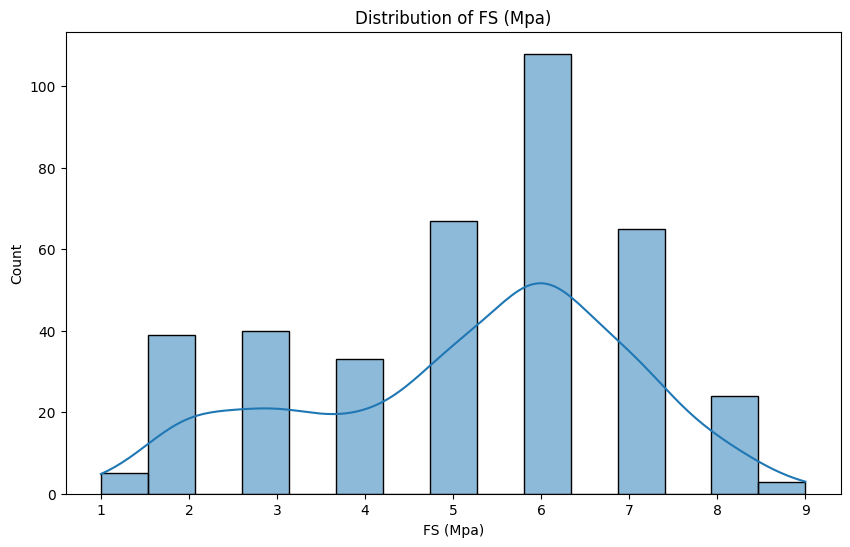

In [35]:
#Distribution of the target variable
plt.figure(figsize=(10, 6))
sns.histplot(data[target], kde=True)
plt.title(f'Distribution of {target}')

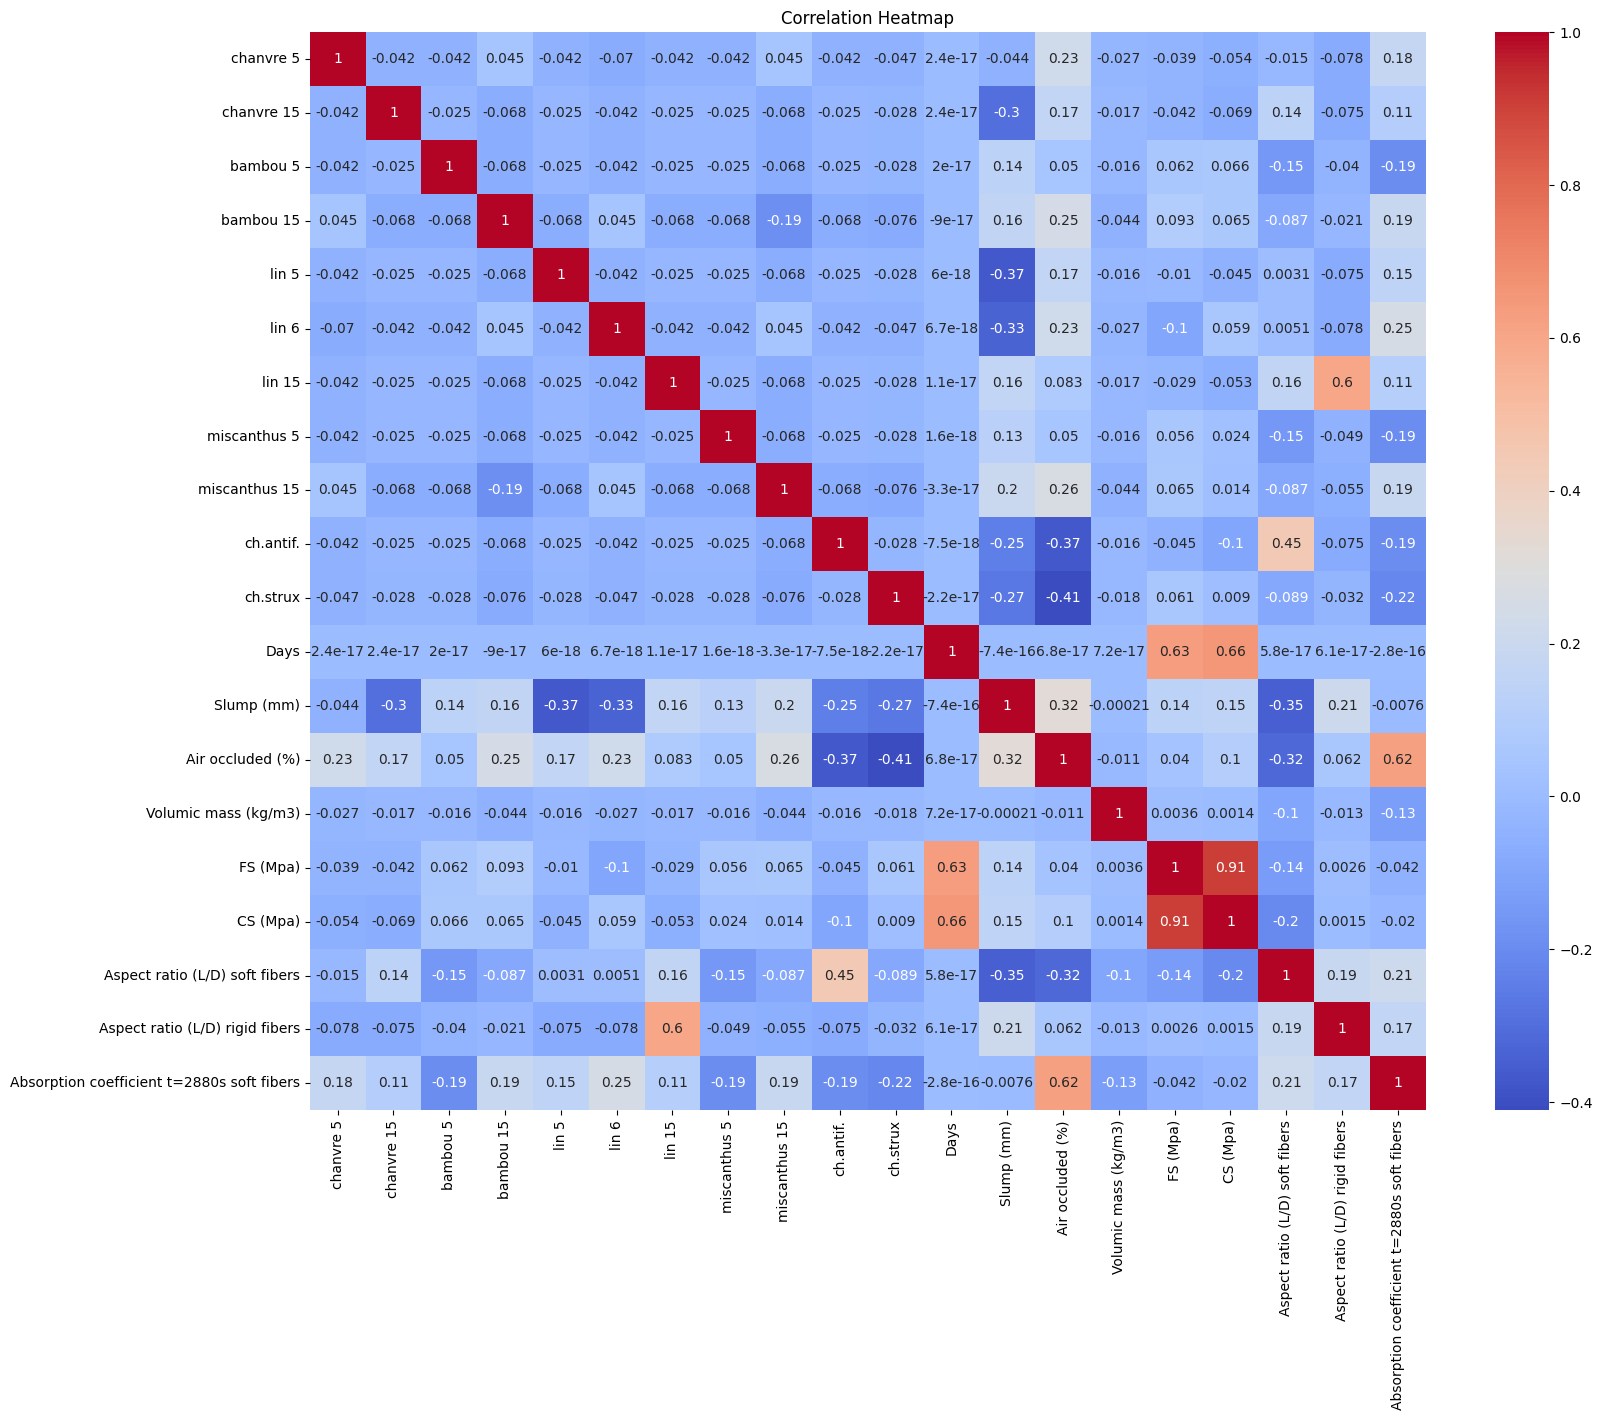

In [36]:
numerical_columns = data.select_dtypes(include=['float64', 'int64']).columns
categorical_columns = data.select_dtypes(include=['object'])

# Correlation heatmap for numerical features
plt.figure(figsize=(18, 14))
sns.heatmap(data[numerical_columns].corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

## 3.2 Distribution of the Target Variable Across Discrete Numerical Features

chanvre 5 has 4 distinct values, distribution by FS (Mpa):


<Figure size 1000x400 with 0 Axes>

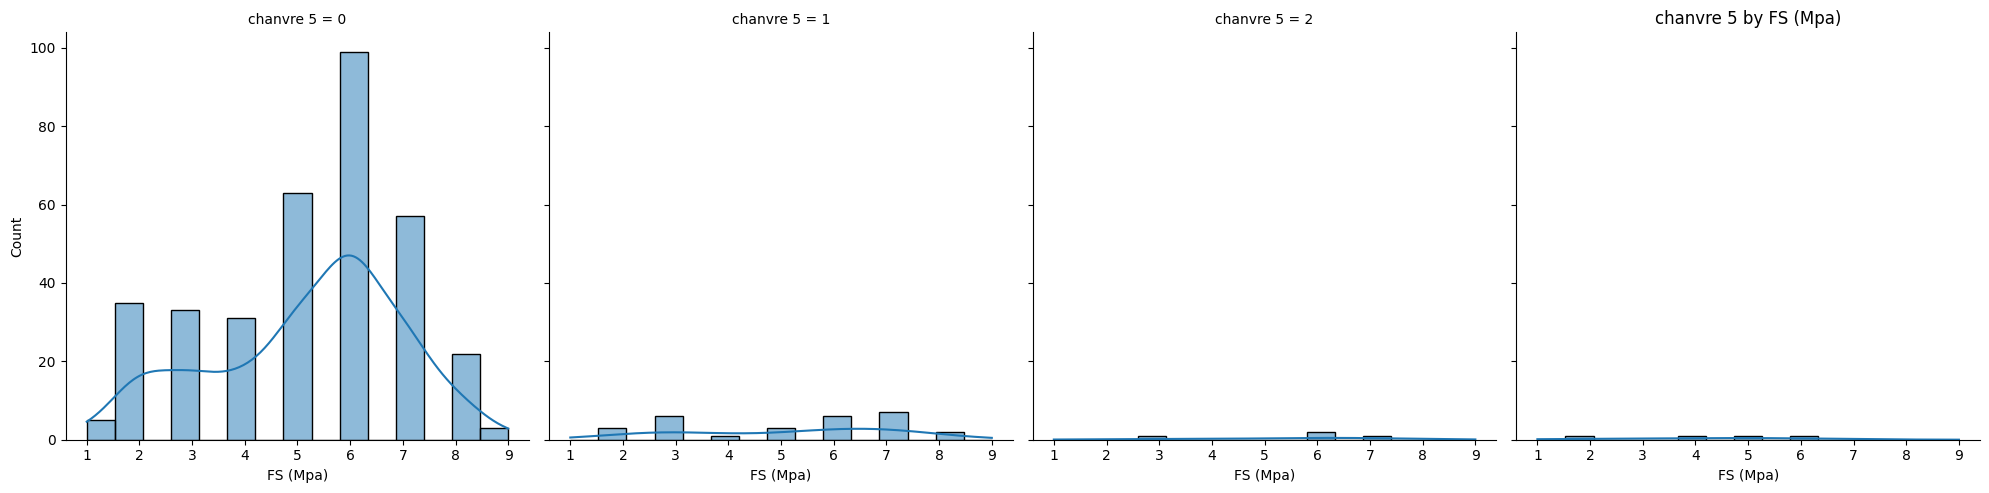

chanvre 15 has 4 distinct values, distribution by FS (Mpa):


<Figure size 1000x400 with 0 Axes>

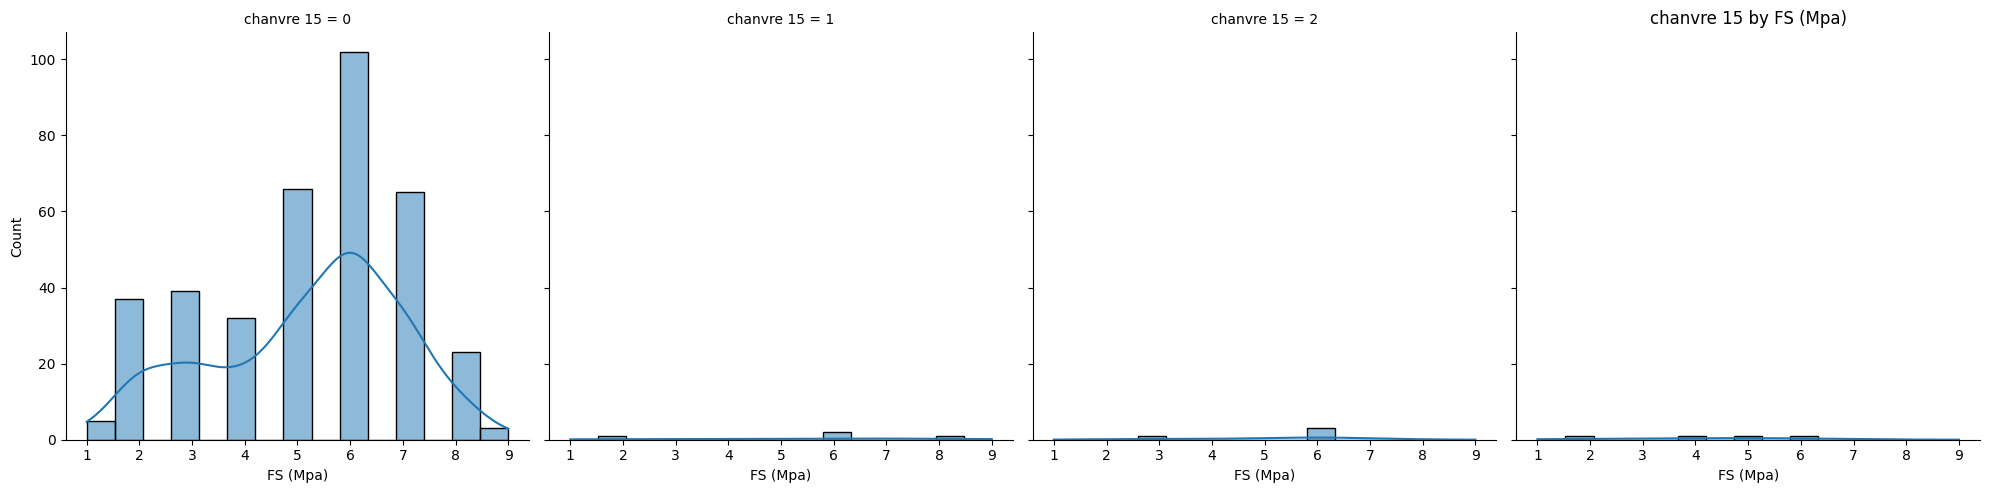

bambou 5 has 4 distinct values, distribution by FS (Mpa):


<Figure size 1000x400 with 0 Axes>

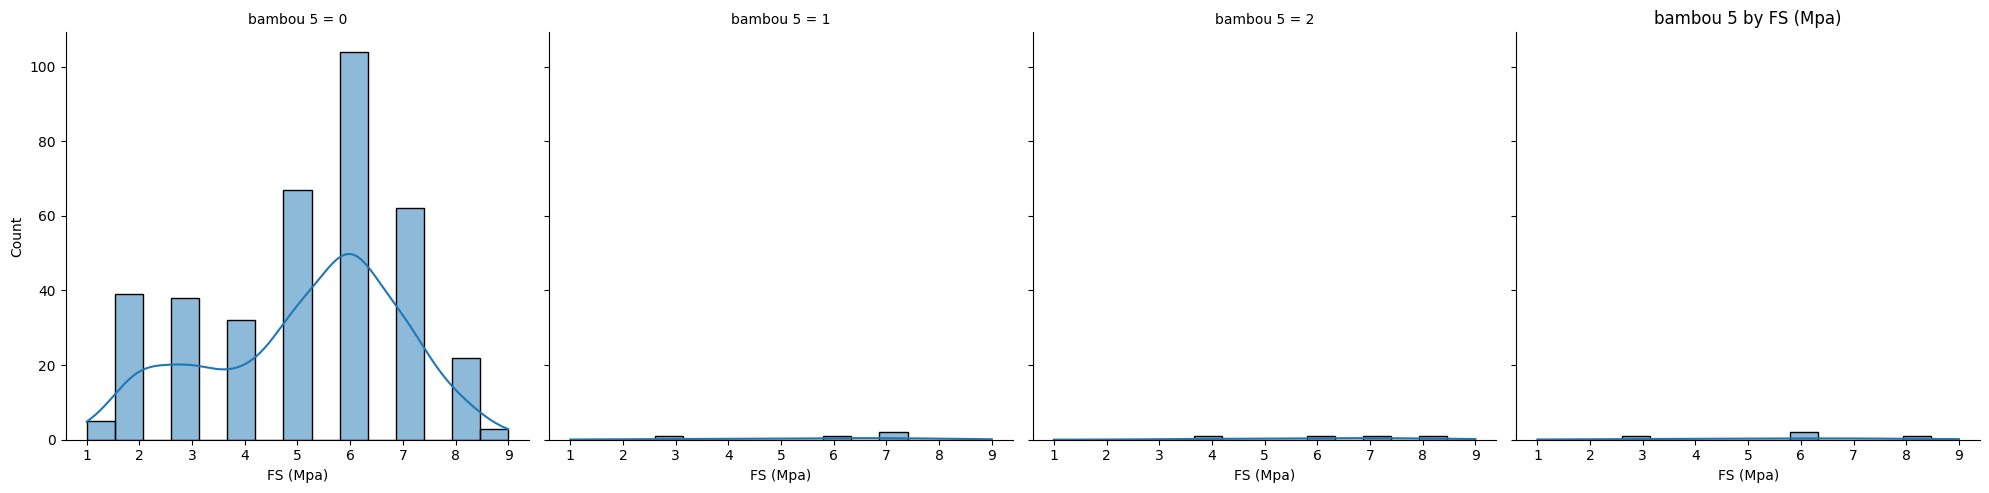

bambou 15 has 5 distinct values, distribution by FS (Mpa):


<Figure size 1000x400 with 0 Axes>

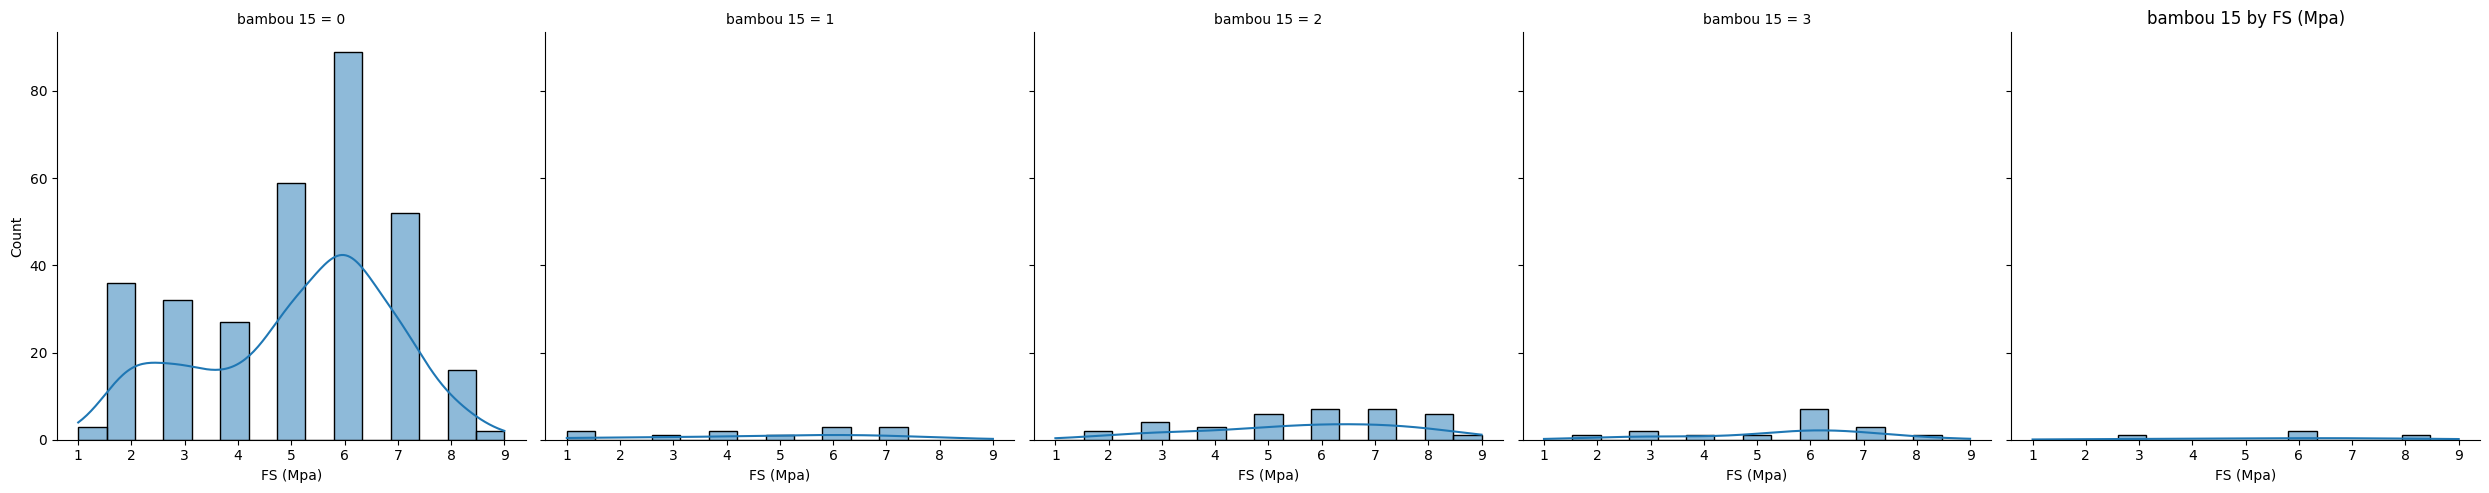

lin 5 has 4 distinct values, distribution by FS (Mpa):


<Figure size 1000x400 with 0 Axes>

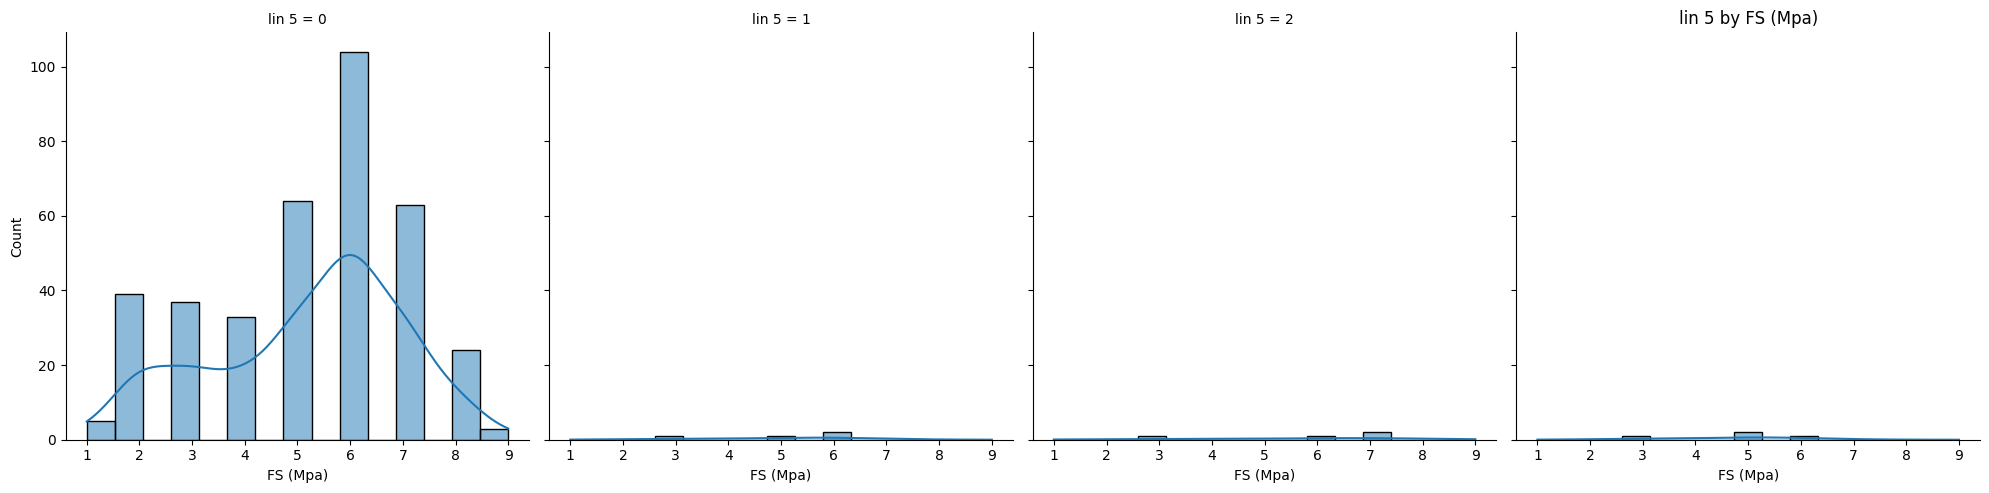

lin 6 has 4 distinct values, distribution by FS (Mpa):


<Figure size 1000x400 with 0 Axes>

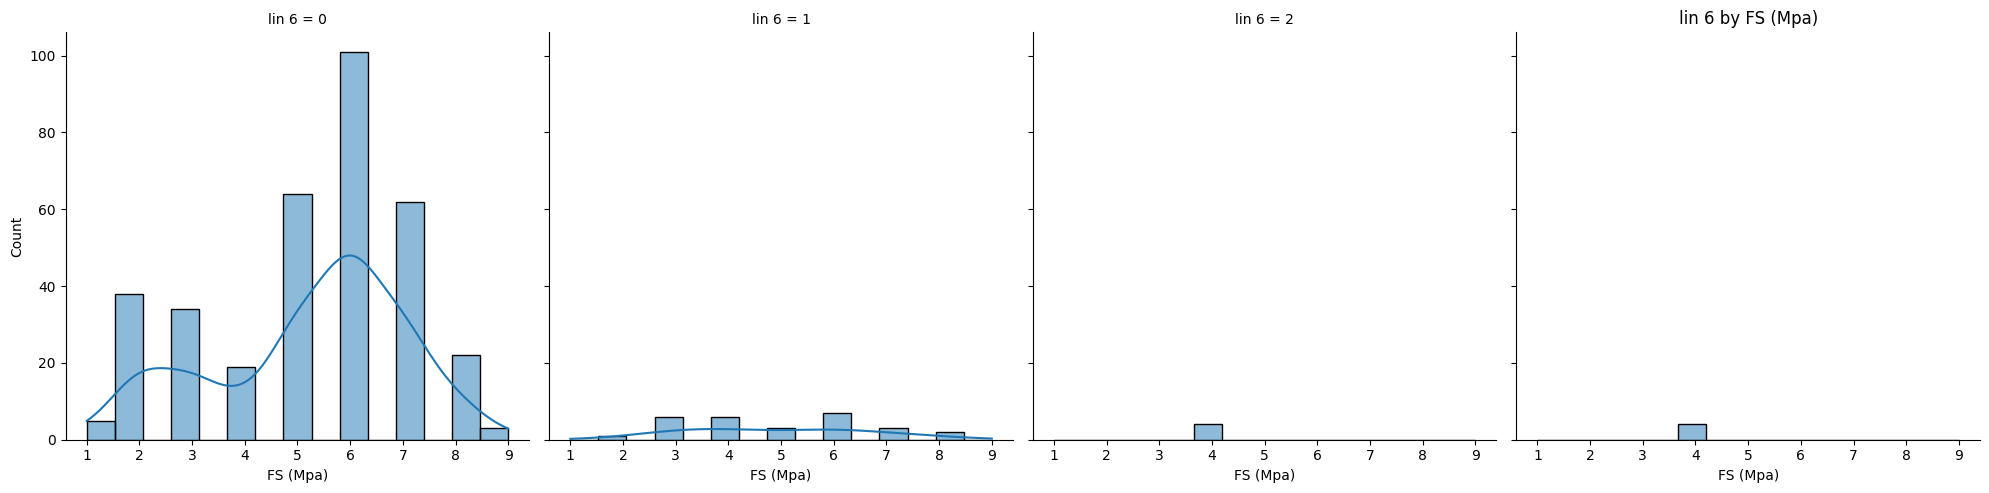

lin 15 has 4 distinct values, distribution by FS (Mpa):


<Figure size 1000x400 with 0 Axes>

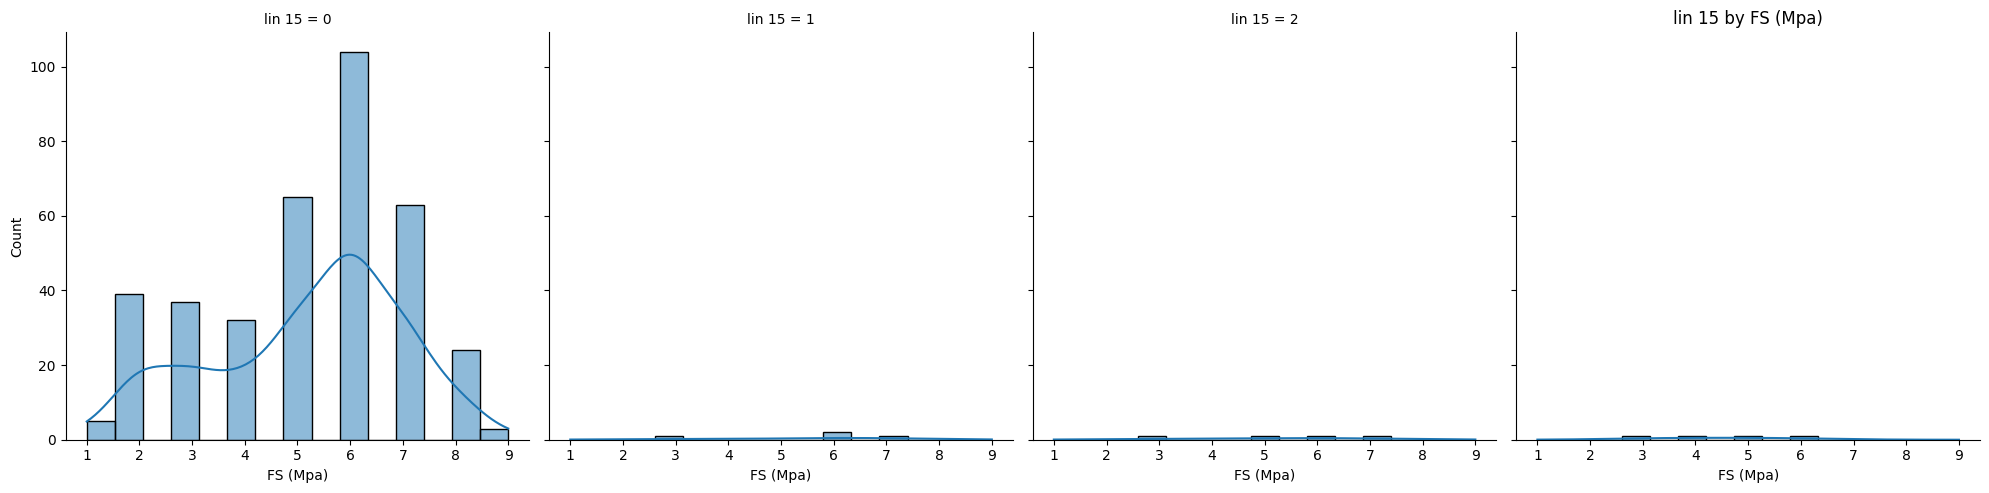

miscanthus 5 has 4 distinct values, distribution by FS (Mpa):


<Figure size 1000x400 with 0 Axes>

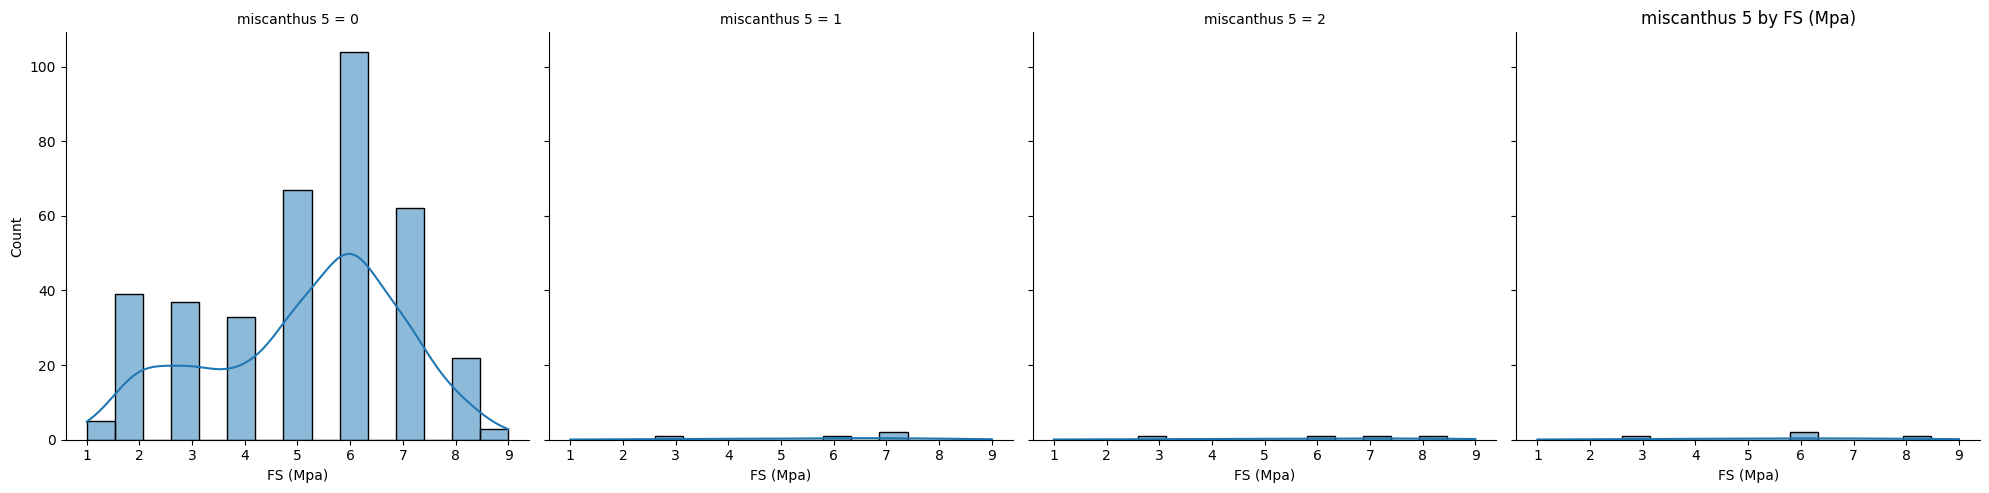

miscanthus 15 has 5 distinct values, distribution by FS (Mpa):


<Figure size 1000x400 with 0 Axes>

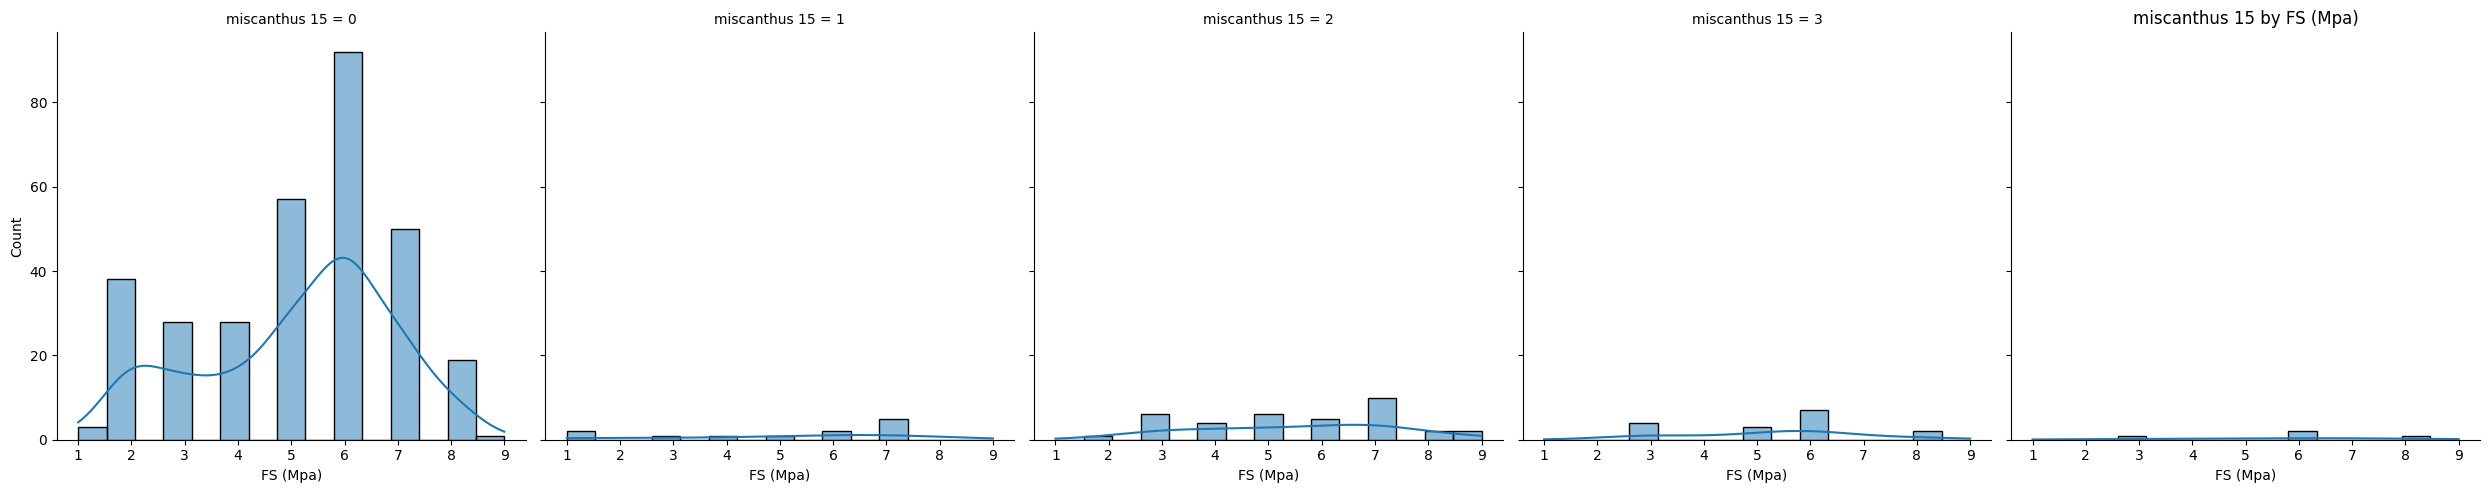

ch.antif. has 4 distinct values, distribution by FS (Mpa):


<Figure size 1000x400 with 0 Axes>

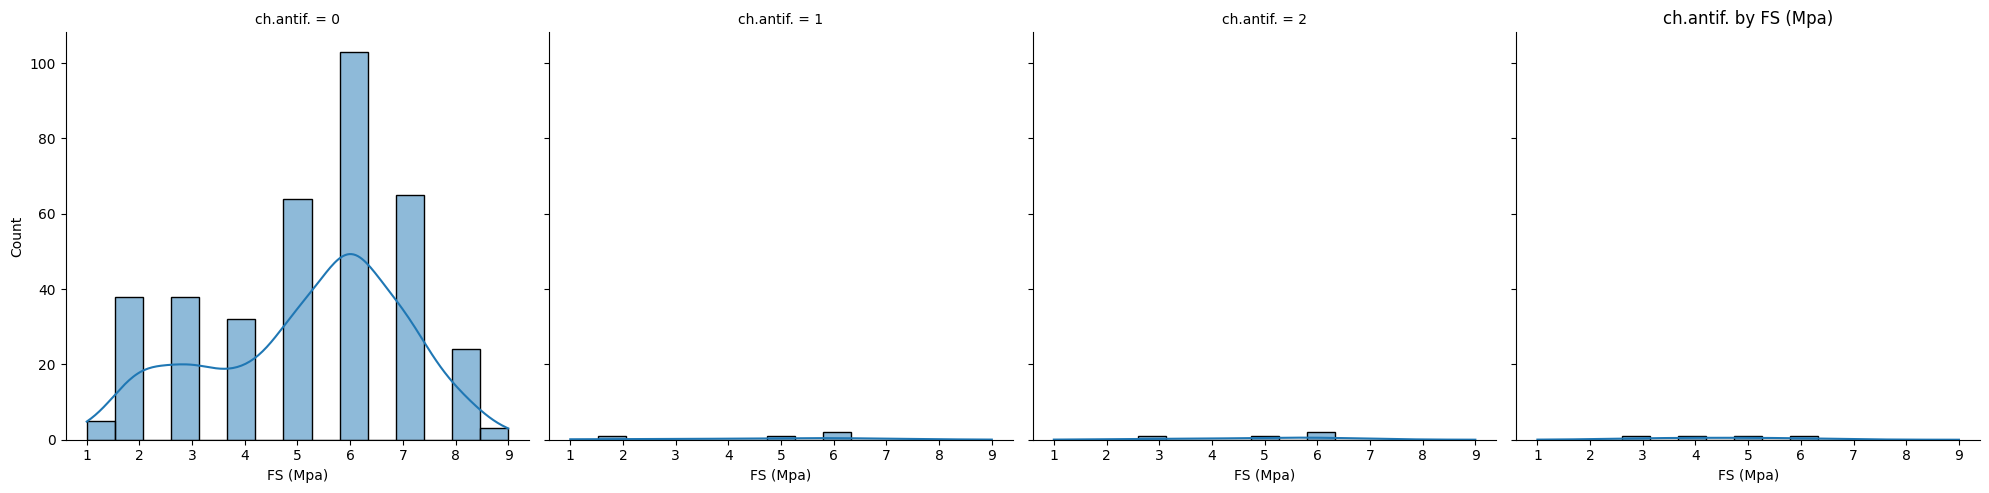

ch.strux has 4 distinct values, distribution by FS (Mpa):


<Figure size 1000x400 with 0 Axes>

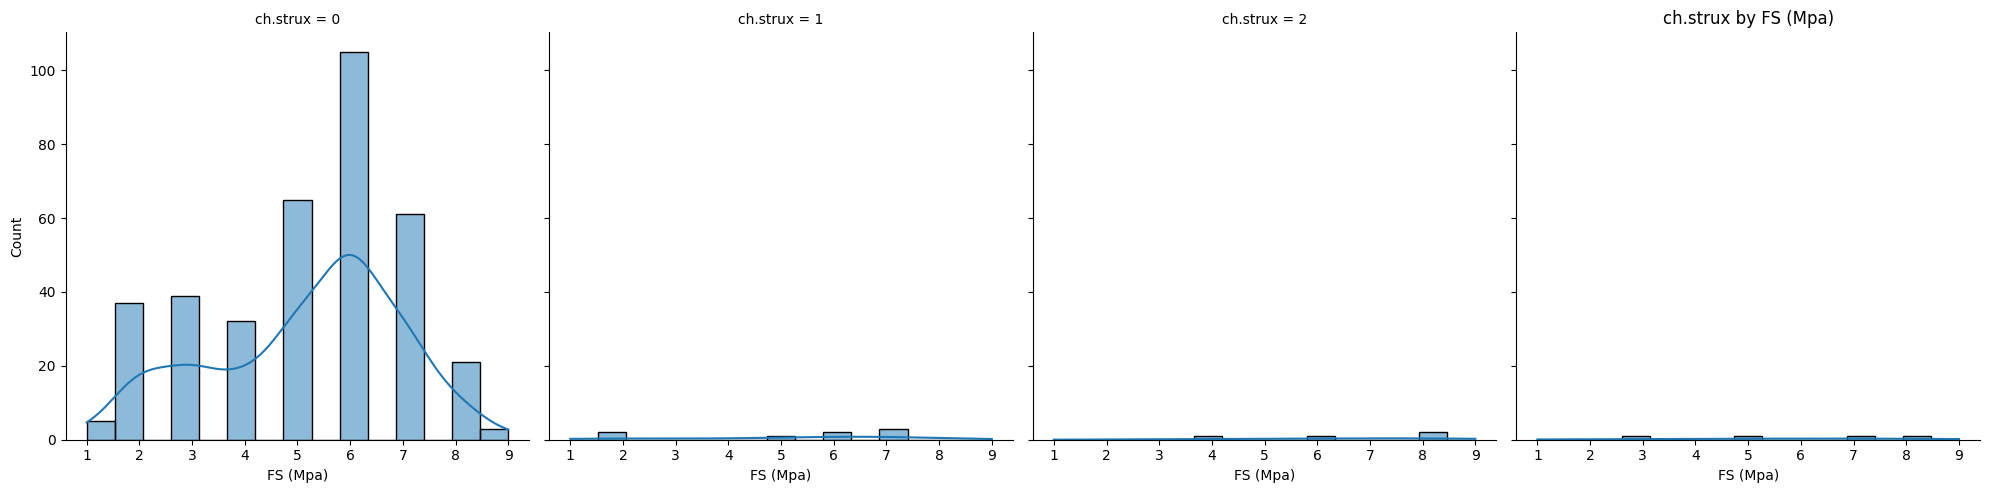

Days has 4 distinct values, distribution by FS (Mpa):


<Figure size 1000x400 with 0 Axes>

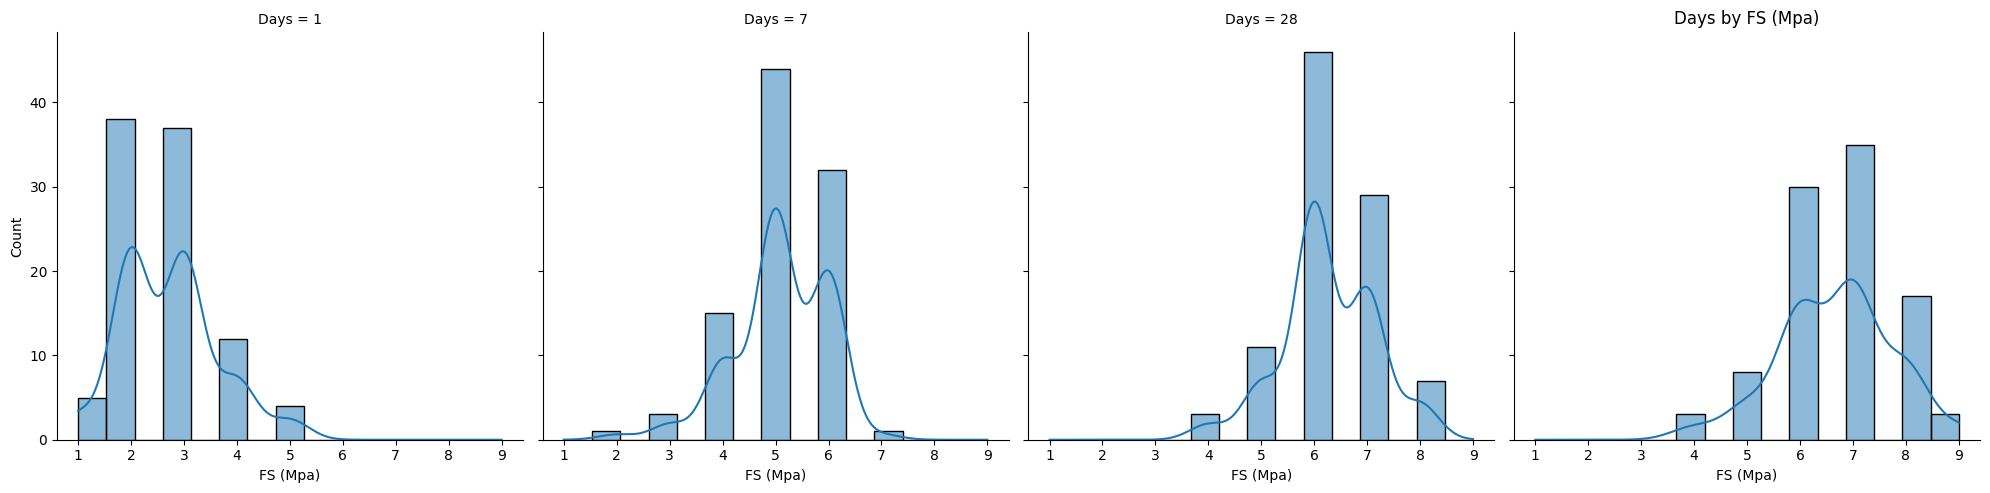

Air occluded (%) has 4 distinct values, distribution by FS (Mpa):


<Figure size 1000x400 with 0 Axes>

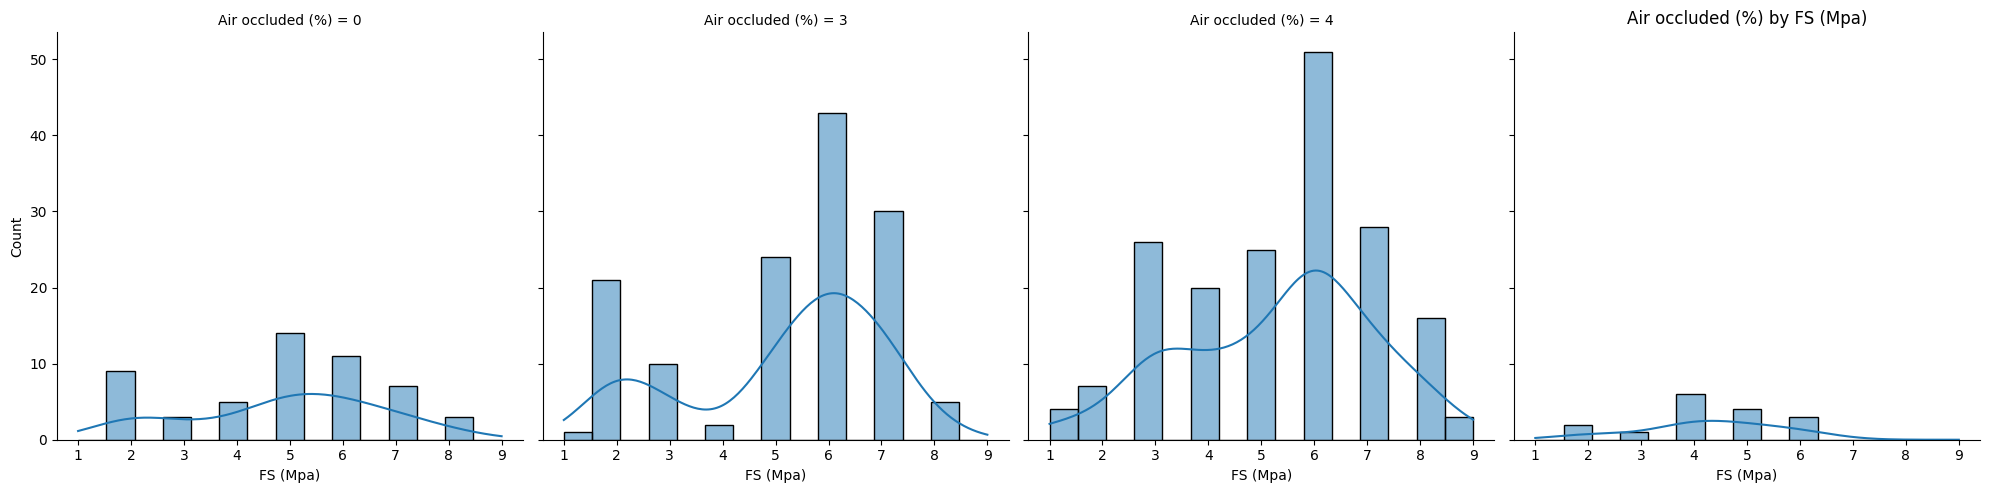

Volumic mass (kg/m3) has 4 distinct values, distribution by FS (Mpa):


<Figure size 1000x400 with 0 Axes>

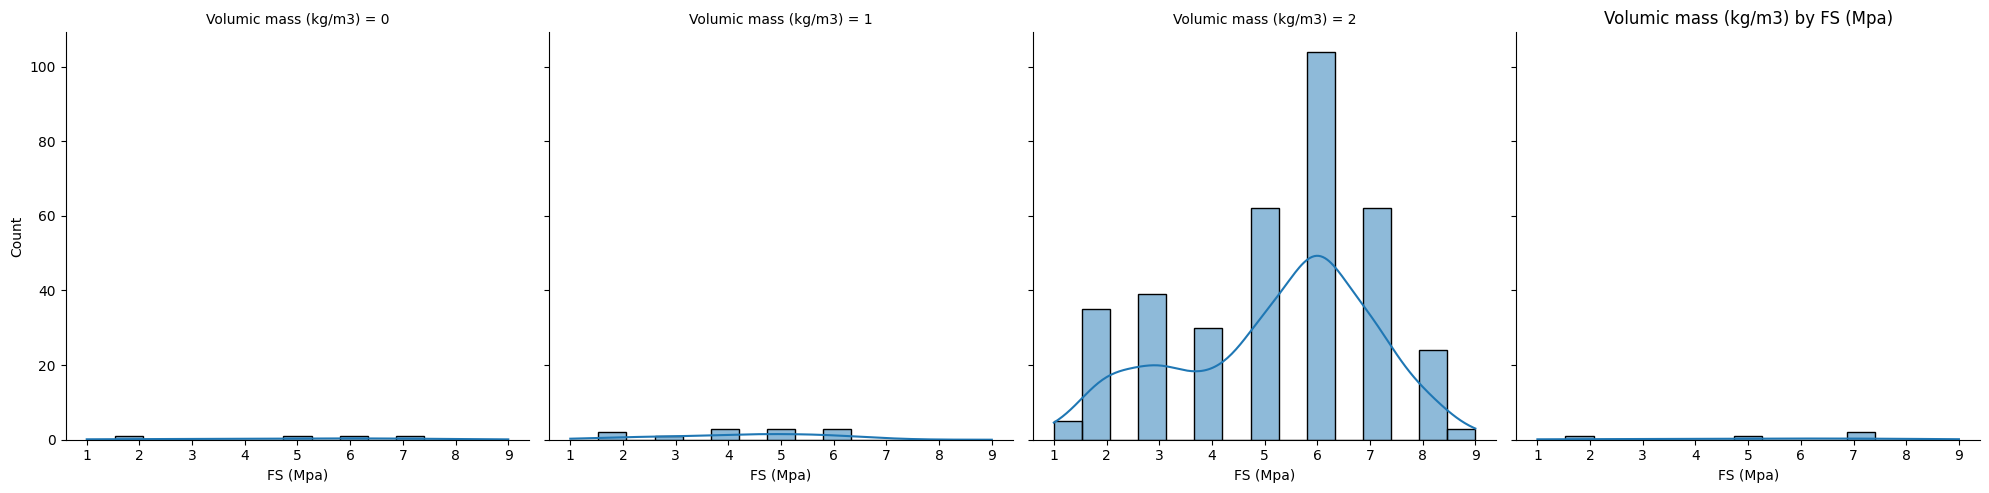

FS (Mpa) has 9 distinct values, distribution by FS (Mpa):


<Figure size 1000x400 with 0 Axes>

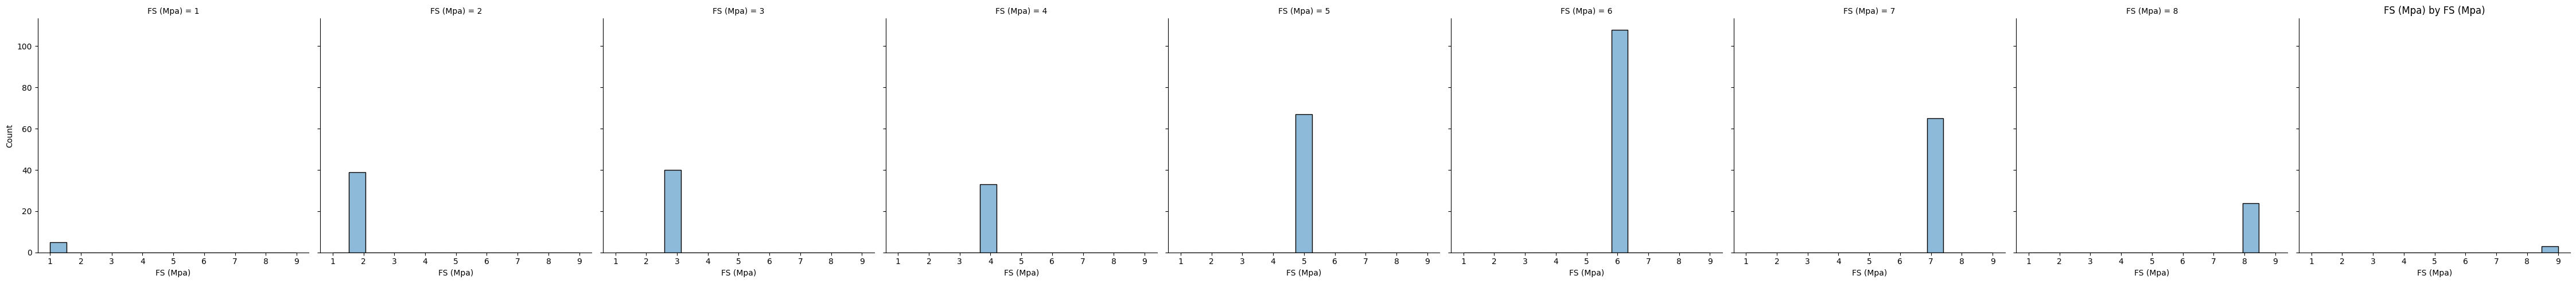

Aspect ratio (L/D) soft fibers has 6 distinct values, distribution by FS (Mpa):


<Figure size 1000x400 with 0 Axes>

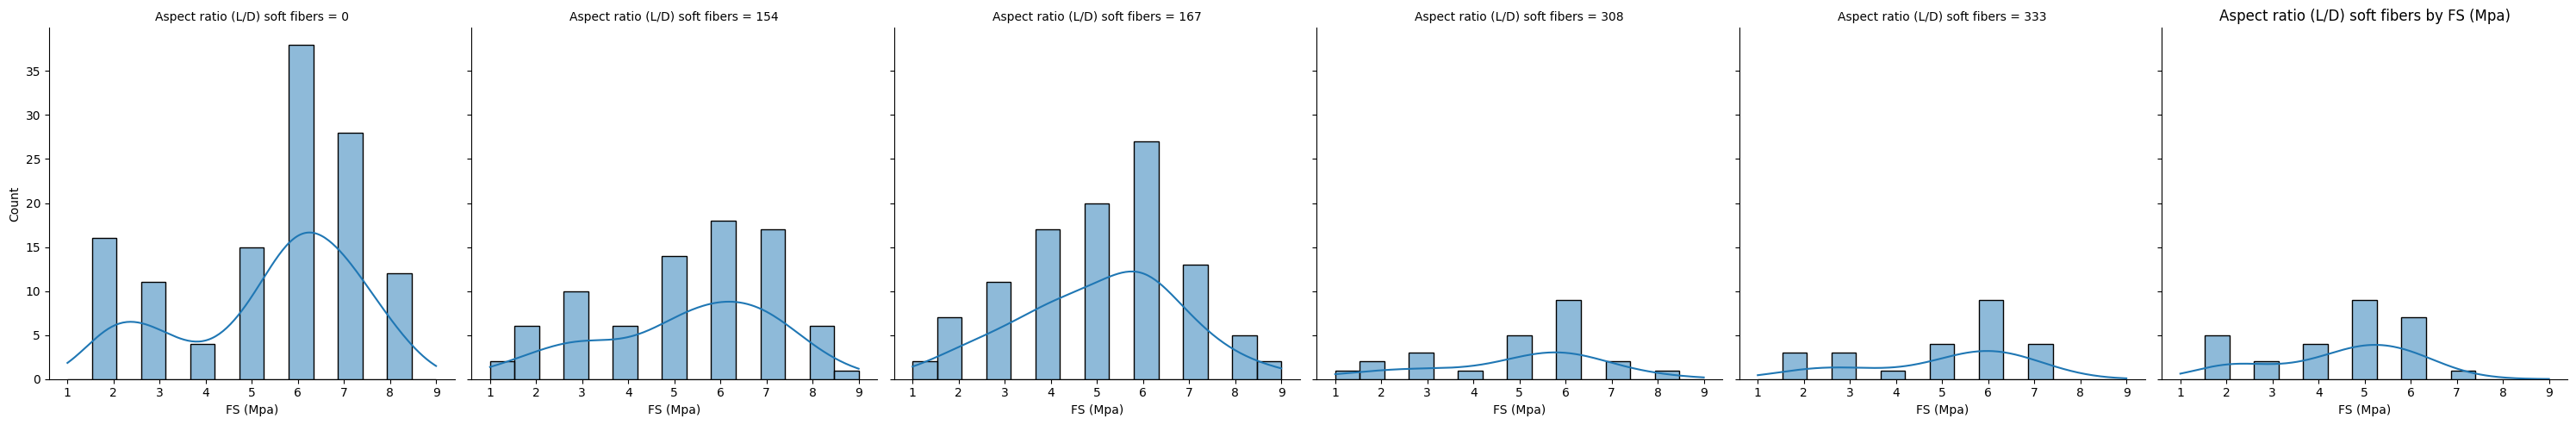

Aspect ratio (L/D) rigid fibers has 7 distinct values, distribution by FS (Mpa):


<Figure size 1000x400 with 0 Axes>

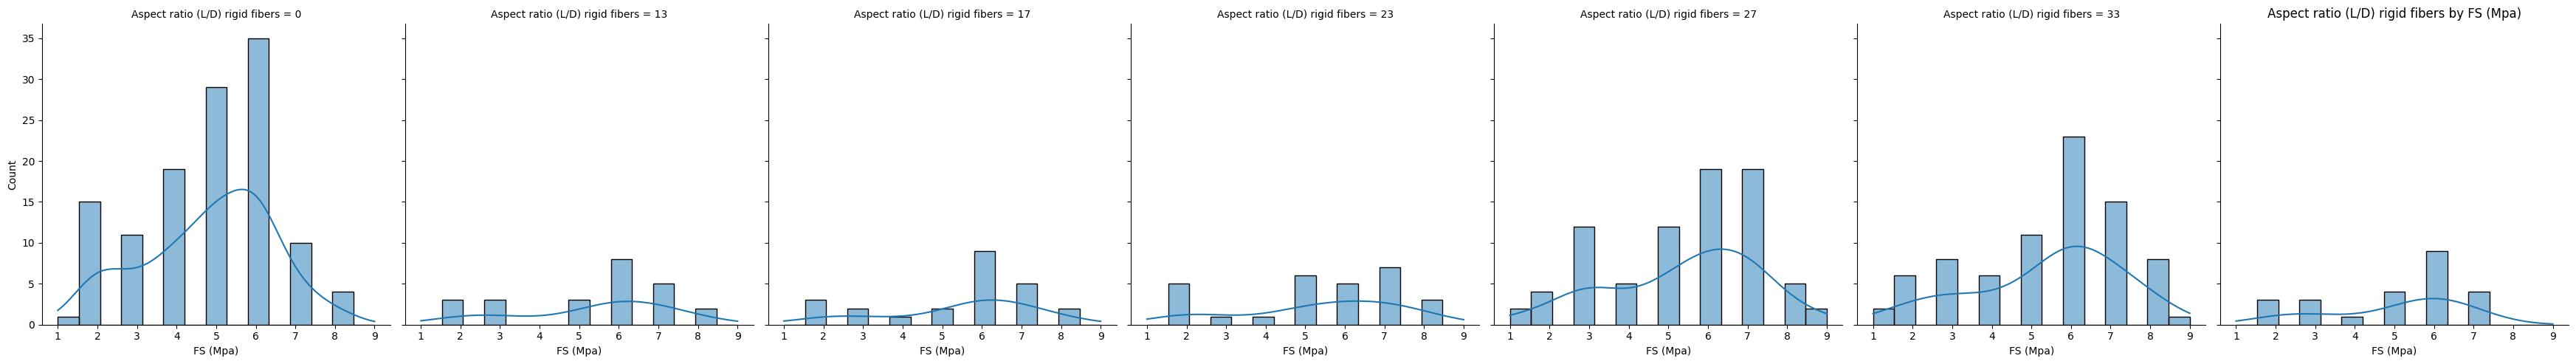

Absorption coefficient t=2880s soft fibers has 5 distinct values, distribution by FS (Mpa):


<Figure size 1000x400 with 0 Axes>

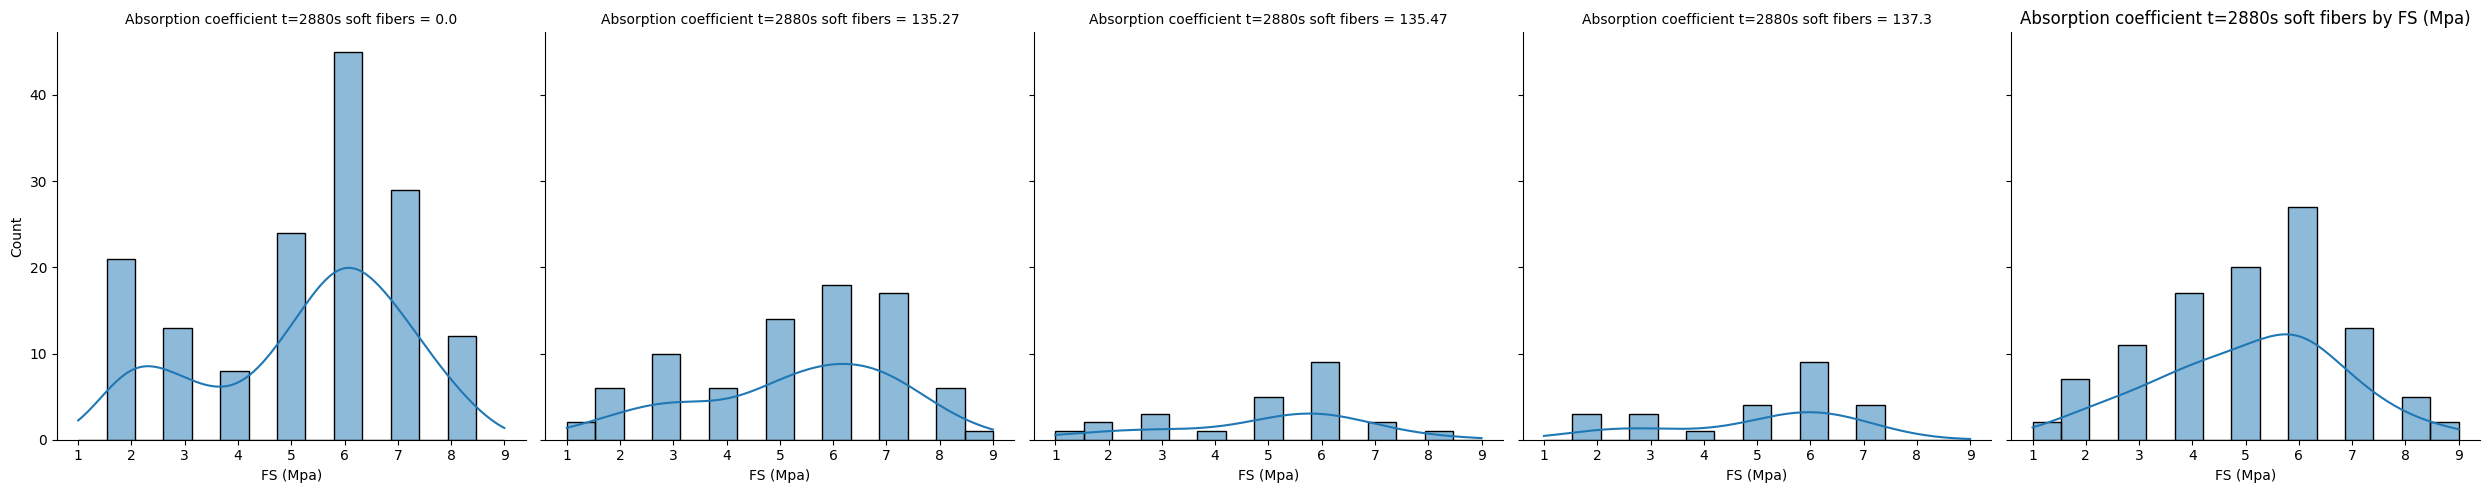

In [37]:
numerical_columns_with_min_distinct_values = [col for col in numerical_columns if data[col].nunique() < 15]
for column in numerical_columns_with_min_distinct_values:
    print(f'{column} has {data[column].nunique()} distinct values, distribution by {target}:')
    plt.figure(figsize=(10, 4))
    sns.displot(data=data, x=target, col=column, kde=True)
    plt.title(f'{column} by {target}')
    plt.show()

## 3.3 Linear / Non-linear Relationships

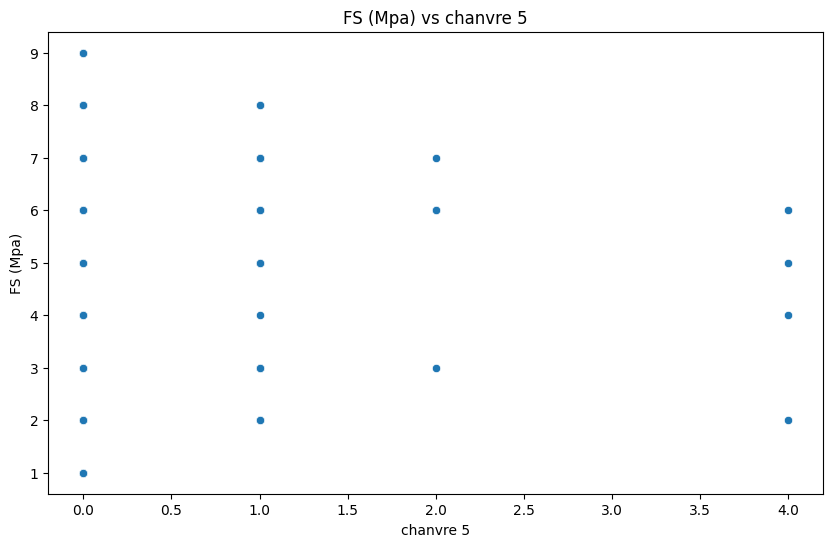

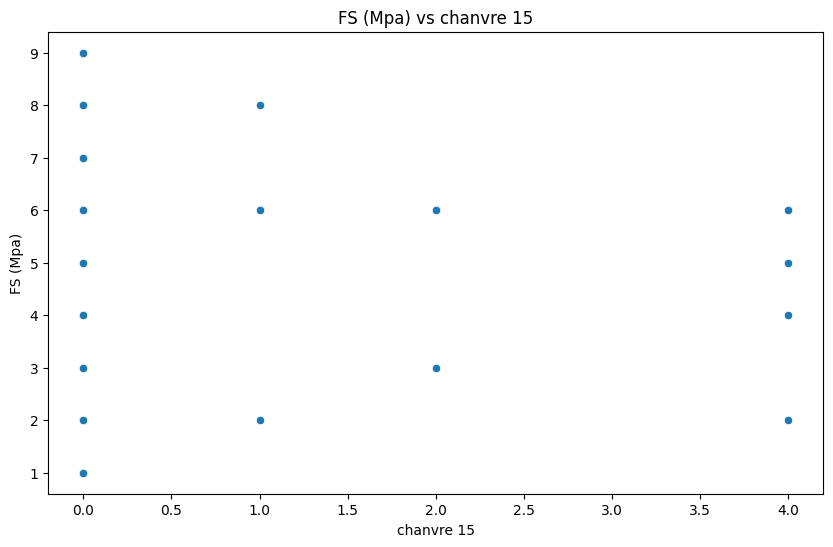

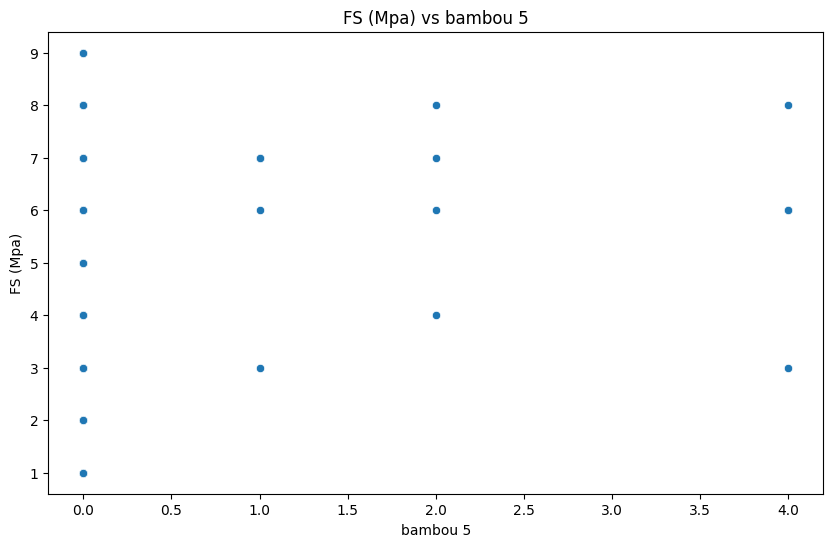

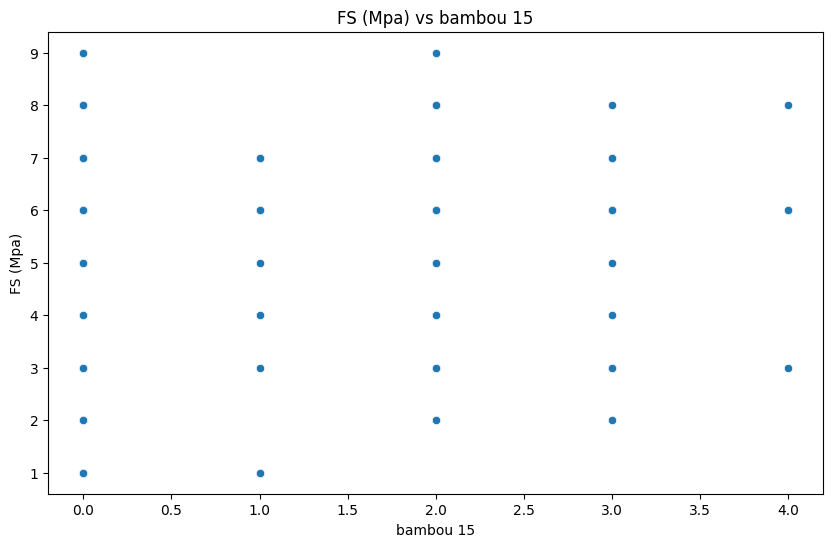

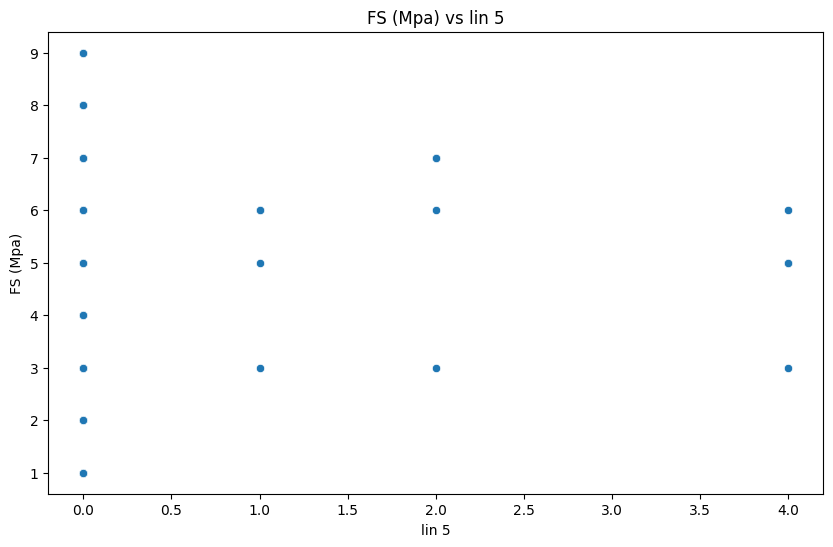

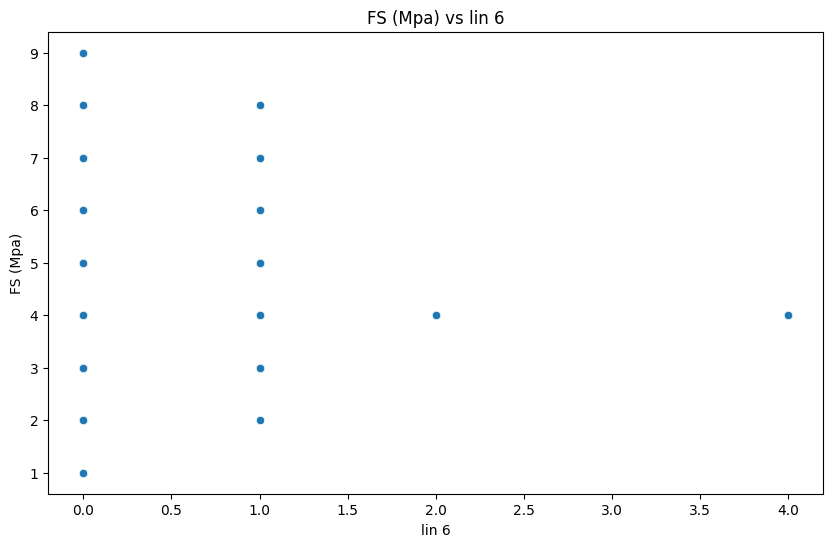

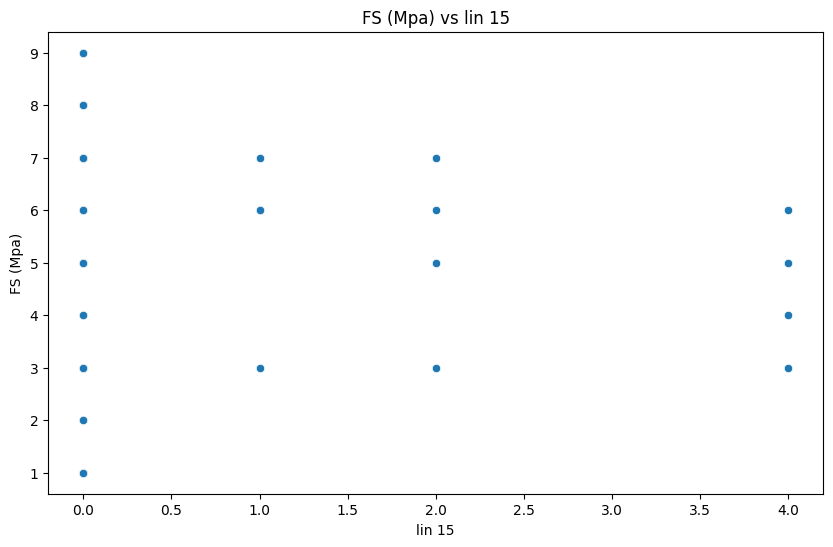

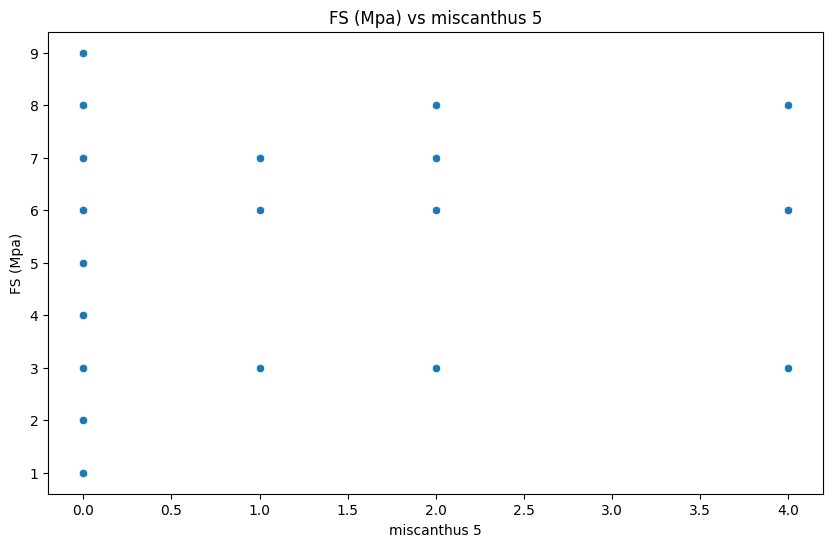

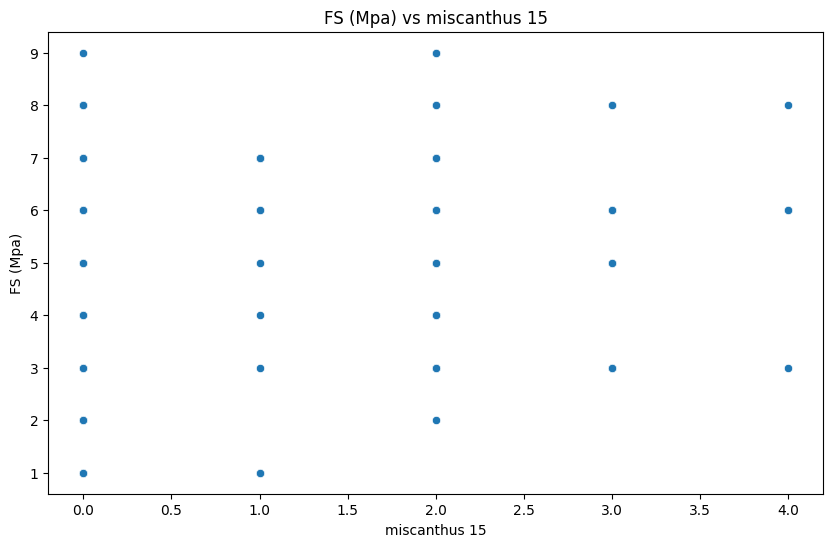

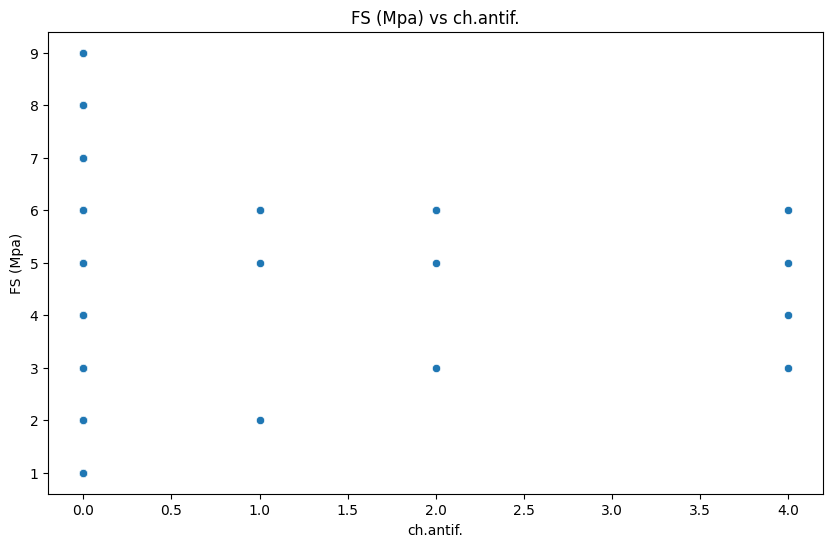

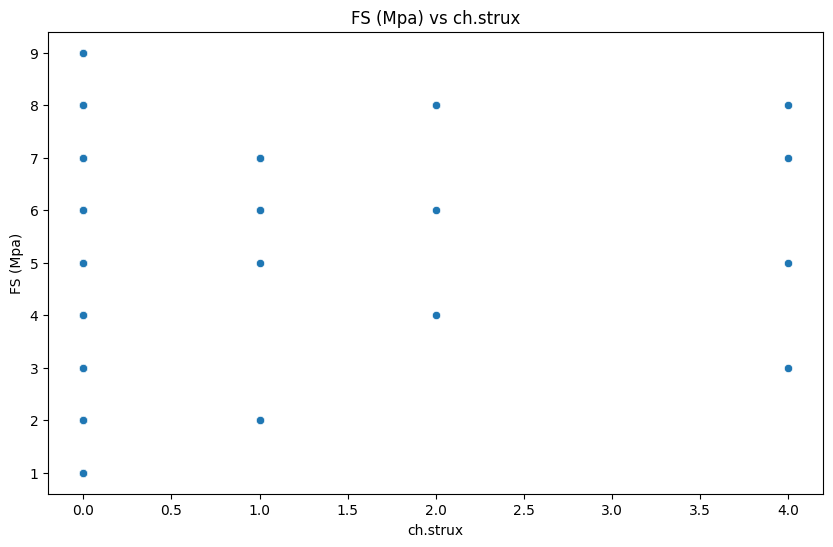

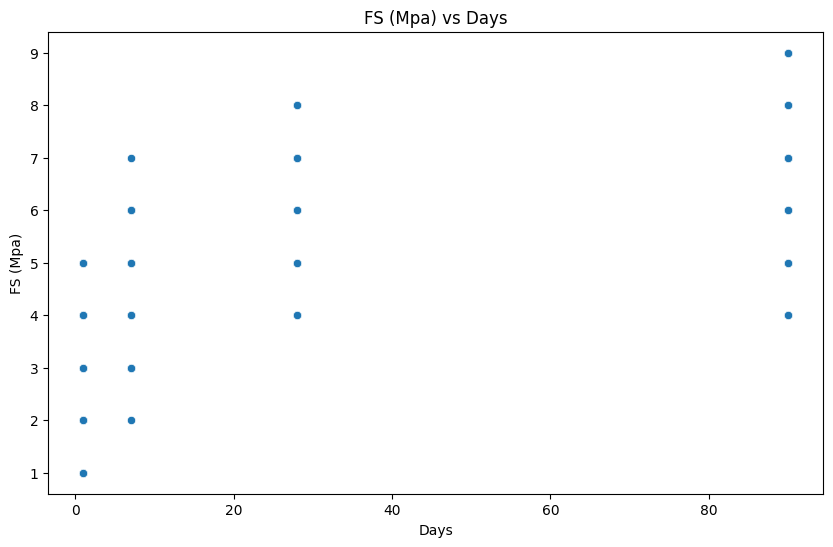

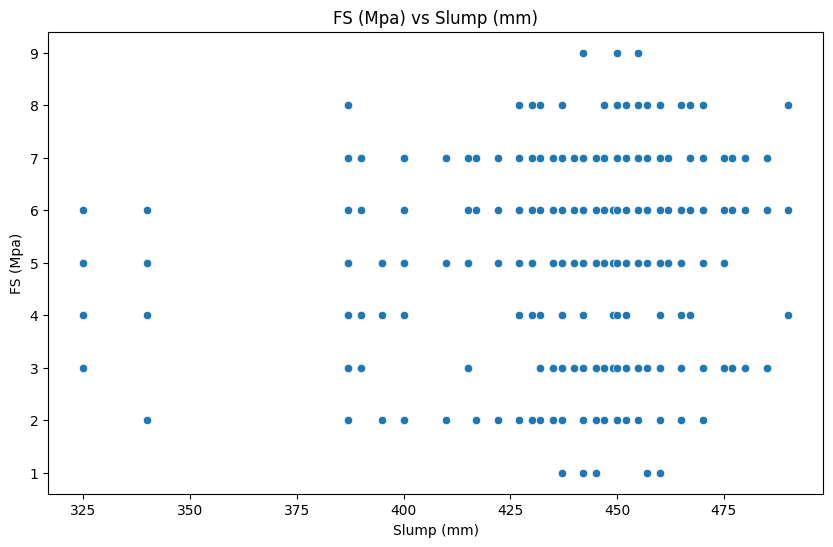

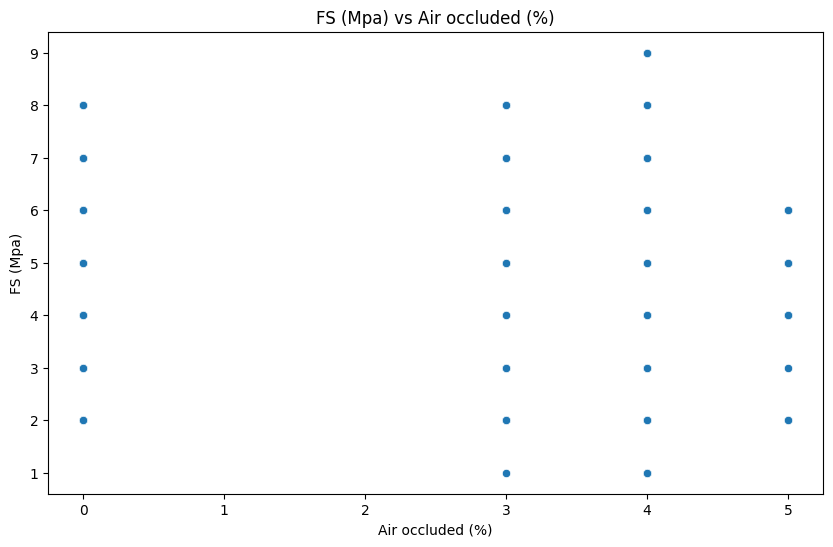

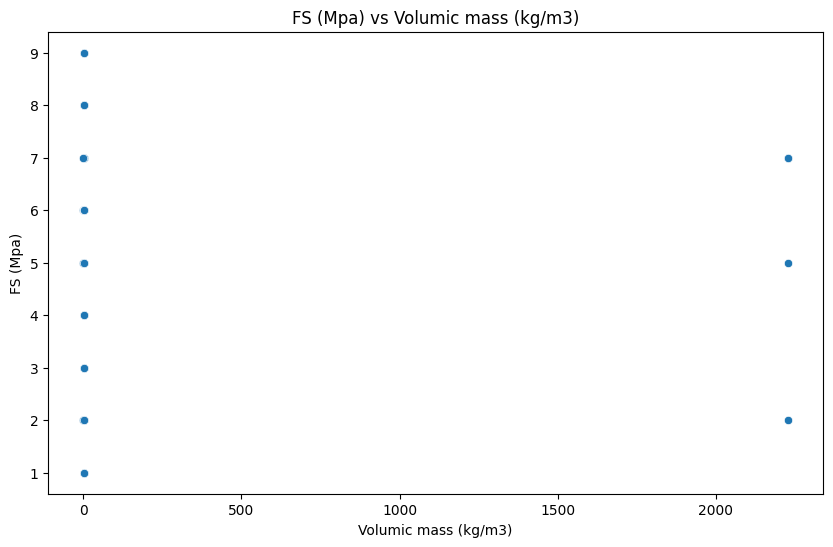

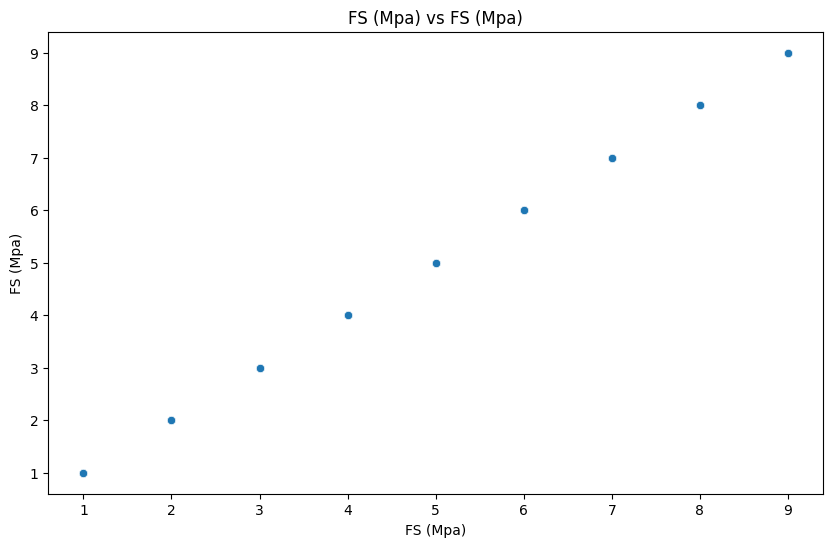

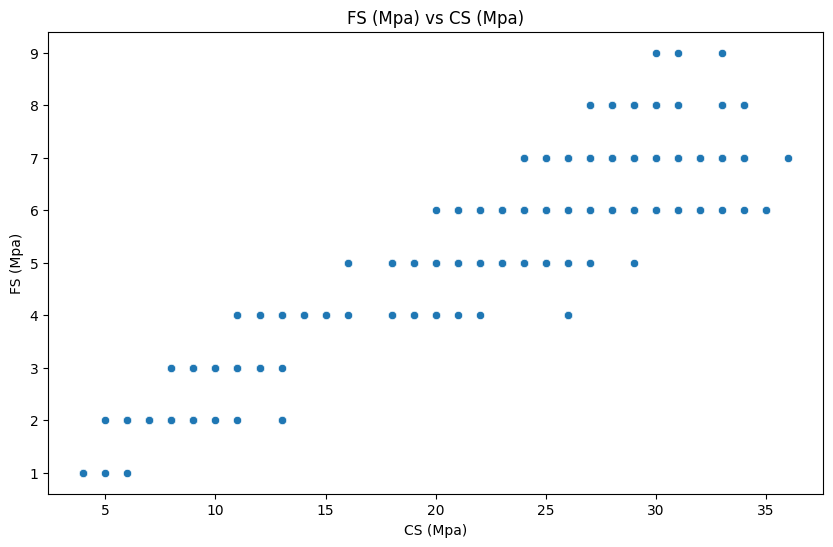

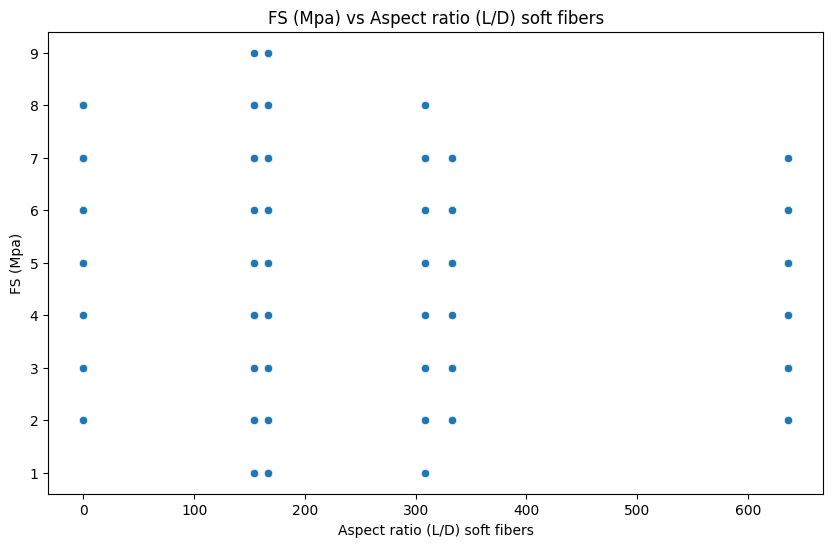

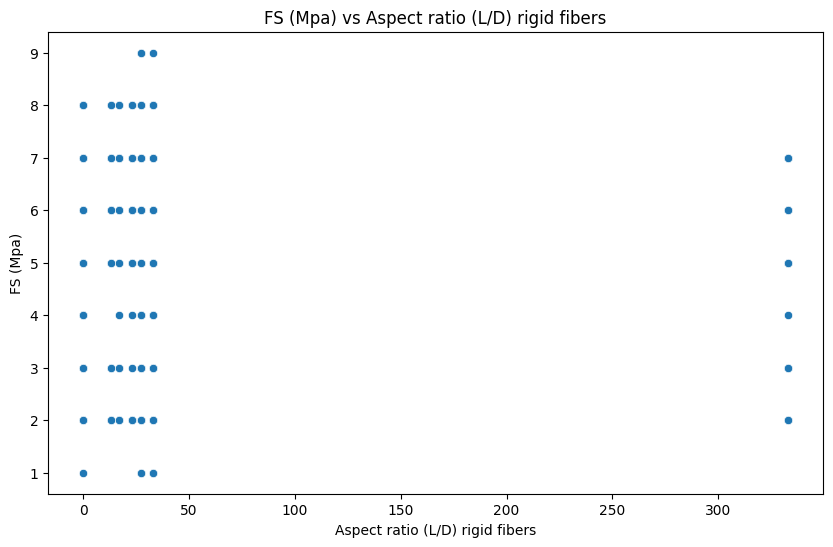

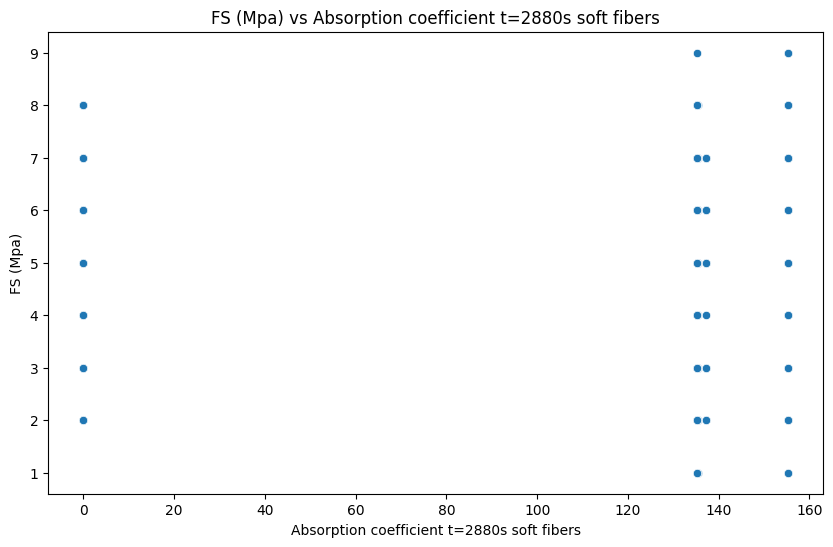

In [38]:
#scatter plots for numerical features vs target scatter plots en fr : nuage de points
cols_to_plot = [col for col in numerical_columns if col not in ['is_temoin'] and 'MEB' not in col]
for column in cols_to_plot:
    plt.figure(figsize=(10, 6))
    sns.scatterplot(x=data[column], y=data[target])
    plt.title(f'{target} vs {column}')
    plt.xlabel(column)
    plt.ylabel(target)
    plt.show()

## 4. Feature Selection and Consistency

<p style="color: grey;">
The column <strong>Rf (MPa) or Rc (Mpa)</strong> depending on the target value is removed to prevent data leakage. Flexural strength and compressive strength are measured simultaneously during the same mechanical test, making them strongly correlated features (r = 0.9388). Keeping Rf as a predictor would give the model information that is unavailable at inference time in a real-world scenario, rendering the prediction of Rc practically meaningless.
</p>

In [39]:
if(target == rc_target):
    print(data[rf_target].corr(data[rc_target]))
    data.drop(rf_target, axis=1, inplace=True)
else: 
    print(data[rc_target].corr(data[rc_target]))
    data.drop(rc_target, axis=1, inplace=True)

1.0


## 6. CSV Export

In [40]:
# export to csv
data.to_csv(f"../data/{file_name}.csv", index=False)